# Annotation des verbatims JDMA par LLM (5 dimensions émotionnelles)

Ce notebook annote `data/verbatim_2026_07_31.csv` avec le prompt de `prompt-LLM.rtf` et quatre LLM open-weights,
puis compare leurs annotations (accord inter-modèles, consensus, lien avec les Z-scores de l'analyse factorielle).

**Organisation**
- L'inférence tourne dans `annotate_llm.py` : **un processus vLLM par modèle, chacun sur son propre GPU H100**.
  Les modèles (22–27B en bf16, ~45–55 Go) tiennent chacun sur une H100 NVL de 94 Go, le reste sert au cache KV.
  Avec 2 GPU libres, les 4 modèles passent en 2 vagues ; avec 4 GPU libres, en une seule.
- Le noyau du notebook n'importe **ni torch ni vLLM** : il ne réserve aucune mémoire GPU et la VRAM est rendue à la fin de chaque processus.
- **Décodage contraint par schéma JSON** (exactement 5 clés, entiers 0–3), **température 0**, « thinking » désactivé (Qwen, Gemma).
- **Reprise sur erreur** : sauvegarde par blocs dans `data/annotations/<RUN_NAME>/<slug>.csv` ; une relance ne traite que les textes manquants.
- Les processus survivent à une interruption du noyau ; leurs journaux sont dans `data/annotations/<RUN_NAME>/logs/`.

**Prérequis** : vLLM dans un environnement séparé (son torch est incompatible avec celui du projet) :
```bash
uv venv ~/venvs/vllm --python 3.12
uv pip install --python ~/venvs/vllm/bin/python vllm pandas
```
Le notebook tourne avec le noyau habituel du projet ; seul `annotate_llm.py` utilise `~/venvs/vllm`.

## Imports et configuration

In [1]:
import json
import os
import signal
import subprocess
import sys
import time
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output, display
from sklearn.metrics import cohen_kappa_score

from annotate_llm import DIMENSIONS, build_messages, parse_scores  # n'importe pas vLLM

# Paramètres

In [2]:

DATA_PATH = Path("../data/verbatim_2026_07_31.csv")
ZSCORES_PATH = Path("../data/Zscores_dimensions.csv")
WORKER = Path("annotate_llm.py").resolve()
WORKER_PYTHON = Path("~/venvs/vllm/bin/python").expanduser()   # environnement dédié à vLLM
HF_HOME = Path("../cache/").resolve()   # même cache que model_trainer.ipynb

# Pilote d'abord : N_SAMPLE textes tirés au hasard (mêmes textes pour les 4 modèles).
# Mettre N_SAMPLE = None pour annoter tout le corpus.
N_SAMPLE = 10000
SEED = 1234
RUN_NAME = (f"pilot_{N_SAMPLE}" if N_SAMPLE else "full") + "_v2"
OUT_DIR = Path("../data/annotations") / RUN_NAME
LOG_DIR = OUT_DIR / "logs"
JOB_DIR = OUT_DIR / "jobs"
for d in (OUT_DIR, LOG_DIR, JOB_DIR):
    d.mkdir(parents=True, exist_ok=True)

# GPU utilisables (index nvidia-smi). Le GPU 1 est utilisé par un autre utilisateur.
# Un GPU de la liste qui n'a pas MIN_FREE_GB de libre est ignoré au lancement.
GPUS = [0, 2, 3]
MIN_FREE_GB = 80             # un GPU avec moins de mémoire libre n'est pas utilisé

CONFIG = {
    "chunk_size": 500,               # textes entre deux sauvegardes
    "max_model_len": 8192,           # le texte le plus long fait ~8 000 caractères (~2 500 tokens)
    "max_new_tokens": 96,            # le JSON de réponse fait ~40 tokens
    "gpu_memory_utilization": 0.90,  # part de la VRAM du GPU réservée par vLLM
    "seed": SEED,
}

MODELS = [
    {
        "id": "google/gemma-4-26B-A4B-it",
        "slug": "gemma4_26b_a4b",
        "multimodal": True,
    },
    {
        "id": "mistralai/Mistral-Small-3.2-24B-Instruct-2506",
        "slug": "mistral_small_3_2_24b",
        "multimodal": True,
    },
    {
        "id": "Qwen/Qwen3.6-27B",
        "slug": "qwen3_6_27b",
        "multimodal": True,
    },
    {
        "id": "utter-project/EuroLLM-22B-Instruct-2512",
        "slug": "eurollm_22b_instruct_2512",
        "multimodal": False,
    },
]

# Options vLLM propres à certains modèles (fusionnées avec les options par défaut du script)
VLLM_EXTRA_KWARGS = {
    "mistral_small_3_2_24b": {   # format recommandé par Mistral pour vLLM
        "tokenizer_mode": "mistral",
        "config_format": "mistral",
        "load_format": "mistral",
    },
    "qwen3_6_27b": {             # Qwen accepte aussi la vidéo : on coupe les deux modalités
        "limit_mm_per_prompt": {"image": 0, "video": 0},
        "max_num_seqs": 512,     # modèle hybride Mamba : au plus 586 séquences en parallèle sur une H100
    },
}

# Arguments du chat template : désactive le « thinking » (Qwen3.x, Gemma 4).
# Mistral (tokenizer mistral_common) n'a pas de template Jinja -> None.
DEFAULT_CHAT_TEMPLATE_KWARGS = {"enable_thinking": False}
CHAT_TEMPLATE_KWARGS = {"mistral_small_3_2_24b": None}

## Prompt d'annotation

Repris de `prompt-LLM.rtf`. Le texte à annoter est ajouté à la fin, entre balises `<texte>`.
Le prompt est enregistré avec le run : on ne peut pas mélanger deux versions du prompt dans un même `RUN_NAME`.

In [3]:
PROMPT_ANNOTATION = """Le texte ci-dessous est la narration, par un usager, d'une expérience vécue avec une administration. Utilise uniquement ce texte. Attribue indépendamment un score entier de 0 à 3 à chacune des cinq dimensions suivantes.

Satisfaction : appréciation positive d’une expérience dans laquelle l’usager peut avancer, atteindre son objectif ou surmonter une difficulté. Comprend le contentement, la joie, la gratitude, la confiance, l’apaisement et le soulagement. Une appréciation comme « tout s’est bien passé » suffit à en indiquer la présence ; un résultat favorable décrit sans appréciation ne suffit pas.

Contestation : colère, indignation ou sentiment d’injustice face à un traitement jugé inacceptable et imputé à un acteur (administration, service, agent ou tiers impliqué). L’usager reproche, accuse, dénonce ou réclame une correction : il considère qu’une autre conduite était possible.
- Présente : reproche ou jugement indigné adressé à un acteur (« c’est inadmissible », « on se moque de nous », « honteux »), question rhétorique qui dénonce (« Pourquoi une telle situation ? »), exigence de réparation.
- Absente : description factuelle d’un dysfonctionnement (« le site affiche une erreur », « je n’ai pas eu de réponse ») ; recours ou réclamation décrits sans indignation ; déception sans reproche.
Repères : « dommage que le service ne réponde pas » = 1 ; « c’est inadmissible d’attendre six mois » = 2 ; « c’est un scandale, on se fiche ouvertement des usagers ! » = 3.

Désillusion : déception et affaiblissement de la confiance dans une résolution ou dans l’utilité des efforts engagés. Comprend le découragement, le sentiment d’abandon, l’impuissance, la résignation et le renoncement lorsqu’ils expriment une perte d’espoir.
- Présente : déception explicite (« je suis déçu »), découragement ou lassitude exprimés (« je n’y crois plus », « à quoi bon »), sentiment d’être abandonné (« on nous laisse tomber »).
- Absente : la seule durée de l’attente ou le nombre de démarches, sans expression de découragement ; une colère contre un acteur sans perte d’espoir.
- Distinction : la contestation vise l’acteur fautif (« ils auraient dû »), la désillusion vise l’issue (« ça n’aboutira jamais »). Les deux peuvent coexister ; compte chacune seulement si sa marque propre est présente.
Repères : « un peu déçu par la lenteur » = 1 ; « je suis découragé, je ne crois plus que mon dossier sera traité » = 2 ; « j’abandonne, plus rien ne sert à rien » = 3.

Détresse : inquiétude, anxiété ou angoisse face à une conséquence redoutée dont l’issue reste incertaine. L’usager craint ce qui pourrait lui arriver, ou arriver à un proche.
- Présente : crainte exprimée (« je suis inquiet », « j’ai peur de perdre mon logement », « je ne sais pas comment je vais payer mon loyer »), angoisse, appel à l’aide pressant.
- Absente : situation grave, urgente ou précaire décrite sans crainte exprimée (« je n’ai plus de revenus depuis juillet » seul = 0) ; impatience ou agacement face à l’attente.
- Distinction : la détresse porte sur une menace encore ouverte ; la désillusion sur un espoir déjà perdu.
Repères : « je suis un peu inquiet » = 1 ; « je suis angoissé » = 2 ; « cette angoisse m’empêche de dormir » = 3.

Perplexité : étonnement, surprise, confusion ou doute devant une situation inattendue ou difficile à interpréter. L’usager ne comprend pas ce qui se passe, ce qui est demandé ou comment poursuivre. La perplexité peut être positive, négative ou neutre.
- Présente : incompréhension exprimée (« je ne comprends pas pourquoi on me demande ce document », « je ne sais pas quelle case cocher »), informations contradictoires qui laissent l’usager dans le doute, surprise devant un résultat inattendu.
- Absente : blocage technique décrit sans incompréhension (« le bouton valider est grisé », « le site bug ») ; question rhétorique qui dénonce (relève de la contestation) ; simple demande d’information.
Repères : « je ne suis pas sûr d’avoir bien compris le courrier » = 1 ; « je ne comprends pas pourquoi mon dossier a été refusé » = 2 ; « je suis complètement perdu, chaque interlocuteur me dit le contraire » = 3.

Applique ce barème à chaque dimension :
0 = non exprimée : aucun indice textuel suffisant.
1 = faible : expression légère ou atténuée.
2 = modérée : expression nette, sans marque de forte intensité.
3 = forte : expression très intense.
Mesure l’intensité exprimée, pas ta certitude ni la gravité objective des faits. En cas d’hésitation entre deux scores, choisis le plus bas.

Plusieurs dimensions peuvent coexister, y compris satisfaction et émotions négatives. Tous les scores peuvent être nuls.
Prends en compte toute l’expérience racontée, y compris les émotions passées. Pour chaque dimension, retiens l’intensité la plus élevée clairement exprimée. Une résolution heureuse n’efface pas une inquiétude antérieure. Ne compte pas une émotion niée ou seulement hypothétique.
Réponds uniquement avec un objet JSON valide contenant exactement les clés suivantes et des valeurs entières de 0 à 3 :
{"satisfaction": 0, "contestation": 0, "desillusion": 0, "detresse": 0, "perplexite": 0}
"""

PROMPT_PATH = OUT_DIR / "prompt.txt"
if PROMPT_PATH.exists() and PROMPT_PATH.read_text(encoding="utf-8") != PROMPT_ANNOTATION:
    raise ValueError(f"Le prompt a changé depuis le début du run {RUN_NAME!r} : changer RUN_NAME.")
PROMPT_PATH.write_text(PROMPT_ANNOTATION, encoding="utf-8")

print(build_messages(PROMPT_ANNOTATION, "Exemple de verbatim.")[0]["content"][-300:])

mpte pas une émotion niée ou seulement hypothétique.
Réponds uniquement avec un objet JSON valide contenant exactement les clés suivantes et des valeurs entières de 0 à 3 :
{"satisfaction": 0, "contestation": 0, "desillusion": 0, "detresse": 0, "perplexite": 0}

<texte>
Exemple de verbatim.
</texte>


## Données

In [4]:
verbatim_df = pd.read_csv(DATA_PATH, sep=";", encoding="utf-8-sig")
verbatim_df = verbatim_df.rename(columns={"ID expérience": "id_experience"})
print("Lignes :", len(verbatim_df))

verbatim_df = verbatim_df.drop_duplicates("id_experience")
print("Après dédoublonnage des ID :", len(verbatim_df))

verbatim_df["full_comment"] = (
    verbatim_df["Titre"].fillna("").str.strip()
    + "\n\n"
    + verbatim_df["Description"].fillna("").str.strip()
).str.strip()
verbatim_df = verbatim_df[verbatim_df["full_comment"].str.len() > 0]

CORPUS_PATH = OUT_DIR / "corpus.csv"
if CORPUS_PATH.exists():   # on garde exactement le même échantillon d'une session à l'autre
    corpus_df = pd.read_csv(CORPUS_PATH, dtype={"full_comment": str})
else:
    corpus_df = verbatim_df.sample(n=N_SAMPLE, random_state=SEED) if N_SAMPLE else verbatim_df
    corpus_df = corpus_df[["id_experience", "full_comment"]].reset_index(drop=True)
    corpus_df.to_csv(CORPUS_PATH, index=False)
print("Textes à annoter :", len(corpus_df))
corpus_df["full_comment"].str.len().describe()

Lignes : 160983
Après dédoublonnage des ID : 160962
Textes à annoter : 10000


count    10000.000000
mean       574.471200
std        420.203479
min         42.000000
25%        266.750000
50%        454.000000
75%        747.000000
max       3995.000000
Name: full_comment, dtype: float64

In [5]:
assert parse_scores('{"satisfaction": 0, "contestation": 2, "desillusion": 1, "detresse": 0, "perplexite": 3}')["parse_ok"]
assert not parse_scores("pas de json")["parse_ok"]
assert not parse_scores('{"satisfaction": 5}')["parse_ok"]

## Lancement des annotations (un processus par GPU)

In [6]:
def output_path(model: dict) -> Path:
    return OUT_DIR / f"{model['slug']}.csv"


def n_done(model: dict) -> int:
    path = output_path(model)
    if not path.exists():
        return 0
    return pd.read_csv(path, usecols=["id_experience"])["id_experience"].nunique()


def is_complete(model: dict) -> bool:
    return n_done(model) >= len(corpus_df)


def worker_pid(model: dict):
    """PID du processus d'annotation s'il tourne encore (y compris lancé avant un redémarrage du noyau)."""
    pid_file = LOG_DIR / f"{model['slug']}.pid"
    if not pid_file.exists():
        return None
    pid = int(pid_file.read_text())
    try:
        os.kill(pid, 0)
    except OSError:
        return None
    return pid


def gpu_status() -> pd.DataFrame:
    out = subprocess.run(
        ["nvidia-smi", "--query-gpu=index,name,memory.used,memory.total,utilization.gpu",
         "--format=csv,noheader,nounits"],
        capture_output=True, text=True, check=True,
    ).stdout
    rows = [[x.strip() for x in line.split(",")] for line in out.strip().splitlines()]
    df = pd.DataFrame(rows, columns=["gpu", "name", "used_mib", "total_mib", "util_%"])
    df[["gpu", "used_mib", "total_mib"]] = df[["gpu", "used_mib", "total_mib"]].astype(int)
    df["free_gb"] = ((df["total_mib"] - df["used_mib"]) / 1024).round(1)
    return df.set_index("gpu")


def launch(model: dict, gpu: int) -> subprocess.Popen:
    job = {
        "model": model,
        "config": CONFIG,
        "vllm_kwargs": VLLM_EXTRA_KWARGS.get(model["slug"], {}),
        "chat_template_kwargs": CHAT_TEMPLATE_KWARGS.get(model["slug"], DEFAULT_CHAT_TEMPLATE_KWARGS),
        "corpus": str(CORPUS_PATH.resolve()),
        "prompt": str(PROMPT_PATH.resolve()),
        "output": str(output_path(model).resolve()),
    }
    job_path = JOB_DIR / f"{model['slug']}.json"
    job_path.write_text(json.dumps(job, ensure_ascii=False, indent=2), encoding="utf-8")

    env = {
        **os.environ,
        "CUDA_VISIBLE_DEVICES": str(gpu),
        "HF_HOME": str(HF_HOME),
        "TOKENIZERS_PARALLELISM": "false",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    }
    log = open(LOG_DIR / f"{model['slug']}.log", "a")
    log.write(f"\n===== {time.strftime('%Y-%m-%d %H:%M:%S')} — lancement sur GPU {gpu}\n")
    log.flush()
    proc = subprocess.Popen(
        [str(WORKER_PYTHON), str(WORKER), "--job", str(job_path.resolve())],
        stdout=log, stderr=subprocess.STDOUT, env=env,
        start_new_session=True,   # survit à une interruption / un redémarrage du noyau
    )
    (LOG_DIR / f"{model['slug']}.pid").write_text(str(proc.pid))
    return proc


def last_log_line(model: dict) -> str:
    path = LOG_DIR / f"{model['slug']}.log"
    if not path.exists():
        return ""
    lines = [l for l in path.read_text(errors="replace").splitlines() if l.strip()]
    return lines[-1][:140] if lines else ""


def show_progress(assigned: dict | None = None) -> None:
    assigned = assigned or {}
    display(pd.DataFrame([{
        "modèle": m["slug"],
        "GPU": assigned.get(m["slug"], ""),
        "en cours": worker_pid(m) is not None,
        "annotés": n_done(m),
        "total": len(corpus_df),
        "%": round(100 * n_done(m) / len(corpus_df), 1),
        "dernière ligne du journal": last_log_line(m),
    } for m in MODELS]).set_index("modèle"))


def stop_all() -> None:
    """Arrête tous les processus d'annotation de ce run."""
    for m in MODELS:
        pid = worker_pid(m)
        if pid:
            os.killpg(os.getpgid(pid), signal.SIGTERM)
            print(f"Arrêt de {m['slug']} (pid {pid})")

In [7]:
status = gpu_status()
display(status)
usable_gpus = [g for g in GPUS if status.loc[g, "free_gb"] >= MIN_FREE_GB]
print("GPU utilisés pour ce run :", usable_gpus)
if not usable_gpus:
    raise RuntimeError("Aucun GPU de GPUS n'a assez de mémoire libre.")

,name,used_mib,total_mib,util_%,free_gb
gpu,,,,,
0,NVIDIA H100 NVL,119,95830,0,93.5
1,NVIDIA H100 NVL,89505,95830,0,6.2
2,NVIDIA H100 NVL,3,95830,0,93.6
3,NVIDIA H100 NVL,3,95830,0,93.6


GPU utilisés pour ce run : [0, 2, 3]


Ordonnanceur : il remplit les GPU libres avec les modèles restants et rafraîchit l'avancement toutes les `POLL_S` secondes.
Interrompre la cellule **n'arrête pas** les annotations en cours (seulement le lancement des suivants) ; la relancer reprend là où on en était.
Pour tout arrêter : `stop_all()`.

In [8]:
POLL_S = 60


def run_all(models=MODELS, gpus=usable_gpus) -> None:
    queue = [m for m in models if not is_complete(m) and worker_pid(m) is None]
    running = {}   # gpu -> (model, Popen | None)
    for m in models:   # processus lancés lors d'une session précédente
        if worker_pid(m) is not None:
            print(f"{m['slug']} tourne déjà (pid {worker_pid(m)}) : GPU non réutilisé tant qu'il n'a pas fini.")
            running[f"externe:{m['slug']}"] = (m, None)

    failed = []
    while queue or running:
        for key, (m, proc) in list(running.items()):
            finished = (proc.poll() is not None) if proc else (worker_pid(m) is None)
            if finished:
                del running[key]
                if proc and proc.returncode != 0:
                    failed.append(m["slug"])
        free = [g for g in gpus if g not in running]
        # un GPU « externe » occupé bloque une place tant qu'il tourne
        n_external = sum(1 for k in running if isinstance(k, str))
        free = free[: max(0, len(free) - n_external)]
        for gpu in free:
            if not queue:
                break
            m = queue.pop(0)
            running[gpu] = (m, launch(m, gpu))

        clear_output(wait=True)
        print(time.strftime("%H:%M:%S"), "— file d'attente :", [m["slug"] for m in queue] or "vide")
        show_progress({m["slug"]: g for g, (m, _) in running.items() if not isinstance(g, str)})
        if failed:
            print("ÉCHEC :", failed, "-> voir", LOG_DIR)
        if queue or running:
            time.sleep(POLL_S)
    print("Terminé.")


run_all()

12:22:40 — file d'attente : vide


,GPU,en cours,annotés,total,%,dernière ligne du journal
modèle,,,,,,
gemma4_26b_a4b,,False,10000,10000,100.0,[0;36m(MainProcess pid=3250153)[0;0m [33mWA...
mistral_small_3_2_24b,,False,10000,10000,100.0,[0;36m(MainProcess pid=3250154)[0;0m [33mWA...
qwen3_6_27b,,False,10000,10000,100.0,[0;36m(EngineCore pid=3251046)[0;0m [32mINF...
eurollm_22b_instruct_2512,,False,10000,10000,100.0,[0;36m(EngineCore pid=3254544)[0;0m [32mINF...


Terminé.


In [9]:
# Avancement à tout moment (même après un redémarrage du noyau)
show_progress()

,GPU,en cours,annotés,total,%,dernière ligne du journal
modèle,,,,,,
gemma4_26b_a4b,,False,10000,10000,100.0,[0;36m(MainProcess pid=3250153)[0;0m [33mWA...
mistral_small_3_2_24b,,False,10000,10000,100.0,[0;36m(MainProcess pid=3250154)[0;0m [33mWA...
qwen3_6_27b,,False,10000,10000,100.0,[0;36m(EngineCore pid=3251046)[0;0m [32mINF...
eurollm_22b_instruct_2512,,False,10000,10000,100.0,[0;36m(EngineCore pid=3254544)[0;0m [32mINF...


In [10]:
# En cas d'échec : fin du journal d'un modèle
slug = "qwen3_6_27b"
print("\n".join((LOG_DIR / f"{slug}.log").read_text(errors="replace").splitlines()[-40:]))

Capturing CUDA graphs (FULL): 100%|██████████| 51/51 [00:03<00:00, 14.63it/s]
(EngineCore pid=3251046) INFO 10-14 12:03:59 [model_runner.py:1087] Graph capturing finished in 12 secs, took 0.70 GiB
(EngineCore pid=3251046) INFO 10-14 12:03:59 [gpu_worker.py:892] CUDA graph pool memory: 0.7 GiB (actual), 1.48 GiB (estimated), difference: 0.79 GiB (112.3%).
(EngineCore pid=3251046) INFO 10-14 12:03:59 [gpu_worker.py:955] Free memory on device (92.57/93.09 GiB) on startup. Desired GPU memory utilization is (0.9, 83.78 GiB). Actual usage is 51.03 GiB for consumed memory (weights + non-torch), 3.77 GiB for peak activation, and 0.7 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=30208430388` (28.13 GiB) to fit into requested memory, or `--kv-cache-memory=39648681472` (36.93 GiB) to fully utilize gpu memory. Current kv cache memory in use is 28.98 GiB.
(EngineCore pid=3251046) INFO 10-14 12:03:59 [jit_monitor.py:84] Kernel JIT monitor activated; monitore

## Analyse des annotations

Cette partie ne nécessite ni GPU ni vLLM.

In [11]:
SLUGS = [m["slug"] for m in MODELS]

annotations = {}
for m in MODELS:
    path = output_path(m)
    if path.exists():
        df = pd.read_csv(path).drop_duplicates("id_experience", keep="last")
        annotations[m["slug"]] = df
        print(f"{m['slug']:<28} {len(df):>7} textes, parsing OK : {df['parse_ok'].mean():.1%}")
    else:
        print(f"{m['slug']:<28} pas encore annoté")

available = list(annotations)

gemma4_26b_a4b                 10000 textes, parsing OK : 100.0%
mistral_small_3_2_24b          10000 textes, parsing OK : 100.0%
qwen3_6_27b                    10000 textes, parsing OK : 100.0%
eurollm_22b_instruct_2512      10000 textes, parsing OK : 100.0%


In [12]:
# Format long : une ligne par (texte, modèle, dimension)
long_df = pd.concat(
    [df.assign(slug=slug)[["id_experience", "slug", *DIMENSIONS]] for slug, df in annotations.items()]
).melt(id_vars=["id_experience", "slug"], var_name="dimension", value_name="score")

# Format large : une colonne par (dimension, modèle)
wide_df = long_df.pivot_table(index="id_experience", columns=["dimension", "slug"], values="score")

### Distribution des scores par modèle

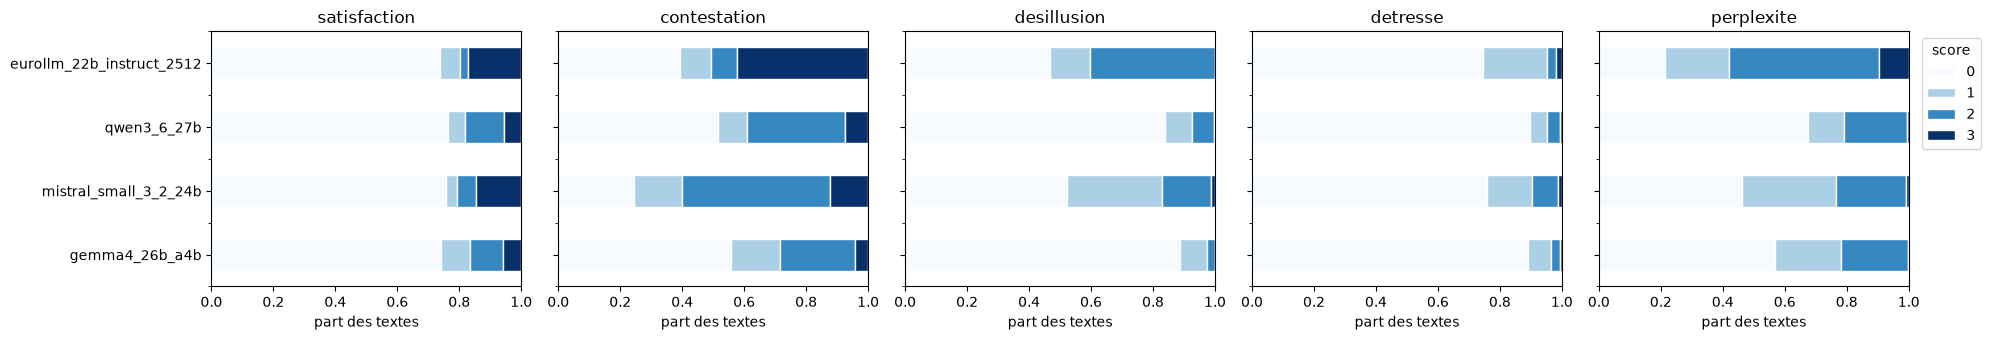

slug,eurollm_22b_instruct_2512,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b
dimension,,,,
contestation,1.54,0.77,1.48,0.95
desillusion,0.94,0.14,0.66,0.24
detresse,0.32,0.15,0.35,0.15
perplexite,1.46,0.65,0.78,0.54
satisfaction,0.63,0.48,0.60,0.47


In [13]:
dist = (
    long_df.dropna()
    .groupby(["dimension", "slug"])["score"]
    .value_counts(normalize=True)
    .unstack("score")
    .reindex(columns=[0, 1, 2, 3])
    .fillna(0)
)
fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4 * len(DIMENSIONS), 3.5), sharey=True)
for ax, dim in zip(axes, DIMENSIONS):
    dist.loc[dim].reindex(available).plot.barh(stacked=True, ax=ax, colormap="Blues", legend=False, edgecolor="white")
    ax.set_title(dim)
    ax.set_xlim(0, 1)
    ax.set_xlabel("part des textes")
    ax.set_ylabel("")
axes[-1].legend(title="score", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

display(long_df.groupby(["dimension", "slug"])["score"].mean().unstack().round(2))

### Accord inter-modèles

- **α de Krippendorff ordinal** sur les 4 modèles, par dimension (> 0,8 : fiable ; 0,667–0,8 : acceptable pour des conclusions prudentes).
- **κ de Cohen pondéré quadratiquement** pour chaque paire de modèles.

In [14]:
def krippendorff_alpha_ordinal(data: np.ndarray, categories=(0, 1, 2, 3)) -> float:
    """data : tableau (annotateurs × items), NaN pour les valeurs manquantes."""
    cats = list(categories)
    k = len(cats)
    idx = {c: i for i, c in enumerate(cats)}
    o = np.zeros((k, k))  # matrice de coïncidences
    for col in data.T:
        vals = [idx[int(v)] for v in col if not np.isnan(v)]
        m = len(vals)
        if m < 2:
            continue
        counts = np.bincount(vals, minlength=k)
        o += (np.outer(counts, counts) - np.diag(counts)) / (m - 1)
    n_c = o.sum(axis=1)
    n = n_c.sum()
    # distance ordinale
    delta = np.zeros((k, k))
    for c in range(k):
        for d in range(k):
            lo, hi = min(c, d), max(c, d)
            delta[c, d] = (n_c[lo:hi + 1].sum() - (n_c[lo] + n_c[hi]) / 2) ** 2
    d_o = (o * delta).sum() / n
    d_e = (np.outer(n_c, n_c) * delta).sum() / (n * (n - 1))
    return 1 - d_o / d_e if d_e > 0 else np.nan


alpha = pd.Series({
    dim: krippendorff_alpha_ordinal(wide_df[dim].reindex(columns=available).to_numpy().T)
    for dim in DIMENSIONS
}, name="alpha_ordinal")
display(alpha.round(3).to_frame())

,alpha_ordinal
satisfaction,0.934
contestation,0.661
desillusion,0.357
detresse,0.585
perplexite,0.489


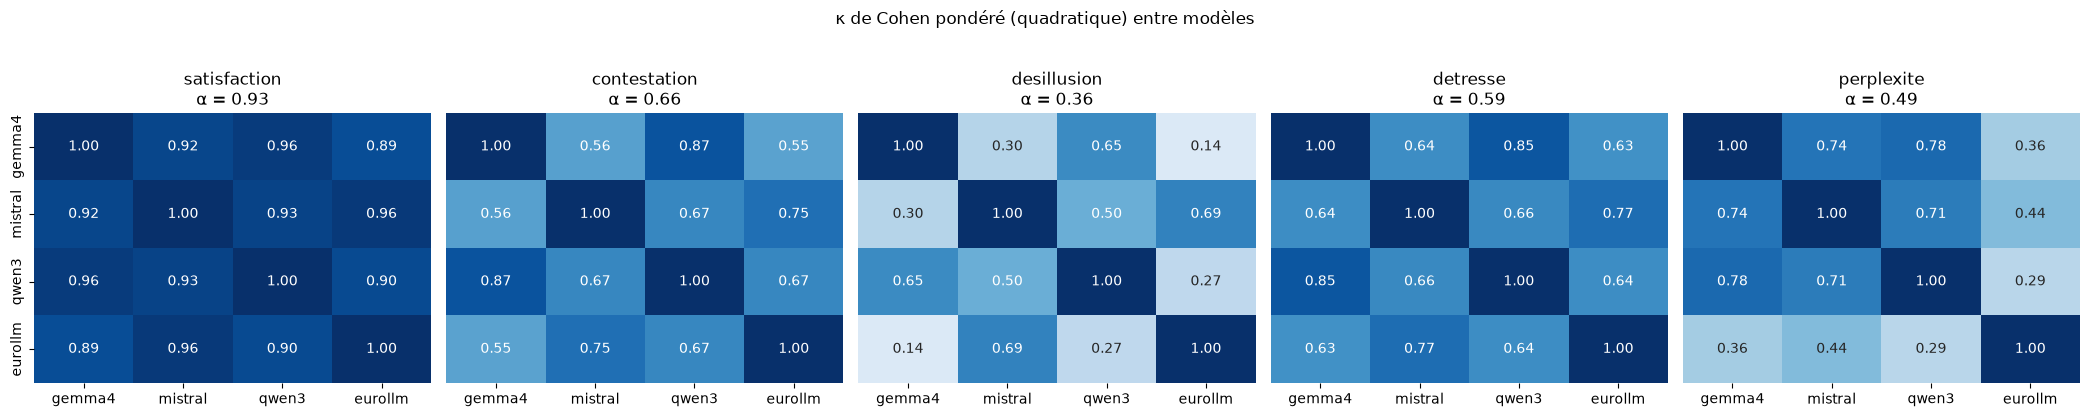

In [15]:
if len(available) >= 2:
    fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4.2 * len(DIMENSIONS), 4))
    for ax, dim in zip(axes, DIMENSIONS):
        mat = pd.DataFrame(np.eye(len(available)), index=available, columns=available)
        for a, b in combinations(available, 2):
            pair = wide_df[dim][[a, b]].dropna()
            mat.loc[a, b] = mat.loc[b, a] = cohen_kappa_score(pair[a], pair[b], weights="quadratic")
        sns.heatmap(mat, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues", cbar=False, ax=ax,
                    xticklabels=[s.split("_")[0] for s in available],
                    yticklabels=[s.split("_")[0] for s in available] if ax is axes[0] else False)
        ax.set_title(f"{dim}\nα = {alpha[dim]:.2f}")
    plt.suptitle("κ de Cohen pondéré (quadratique) entre modèles", y=1.03)
    plt.tight_layout()
    plt.show()

### Consensus

Score de consensus = **médiane** des modèles (arrondie à l'entier inférieur en cas d'égalité 2–2), avec l'écart max entre modèles
pour repérer les textes litigieux à relire.

In [16]:
consensus = pd.DataFrame(index=wide_df.index)
for dim in DIMENSIONS:
    scores = wide_df[dim].reindex(columns=available)
    consensus[dim] = np.floor(scores.median(axis=1))
    consensus[f"{dim}_ecart"] = scores.max(axis=1) - scores.min(axis=1)
    consensus[f"{dim}_n_modeles"] = scores.notna().sum(axis=1)
consensus = consensus.reset_index()
consensus.to_csv(OUT_DIR / "consensus.csv", index=False)

display(pd.DataFrame({
    "écart ≥ 2 (part des textes)": [(consensus[f"{d}_ecart"] >= 2).mean() for d in DIMENSIONS],
    "score consensus moyen": [consensus[d].mean() for d in DIMENSIONS],
}, index=DIMENSIONS).round(3))

,écart ≥ 2 (part des textes),score consensus moyen
satisfaction,0.025,0.487
contestation,0.289,0.996
desillusion,0.332,0.298
detresse,0.039,0.161
perplexite,0.346,0.630


In [17]:
# Textes les plus litigieux, à relire manuellement
ecarts = consensus[[f"{d}_ecart" for d in DIMENSIONS]].sum(axis=1)
litigieux = (
    consensus.assign(ecart_total=ecarts)
    .nlargest(10, "ecart_total")
    .merge(corpus_df, on="id_experience")
)
for _, row in litigieux.iterrows():
    print(f"--- {row['id_experience']} (écart total {row['ecart_total']:.0f})")
    print(row["full_comment"][:600])
    display(wide_df.loc[row["id_experience"]].unstack("slug").reindex(index=DIMENSIONS, columns=available))

--- 6824603 (écart total 12)
J'attends depuis 10 mois le 1er Paiement de l'AAEH

En janvier 25 , la Mdph du 94 a accordé une Aeeh pour mon fils né en 2013. Sur la notification il est indiqué " que le dossier est transmis automatiquement à la CAF de Créteil  , vous n'avez pas de démarches à faire".
En février 25 je reçois 1 mail de la CAF du 94  qui me demande de verser ma pièce d'identité sur mon compte CAF . La je découvre un vieux compte Caf ou rien n'est à jour et qui est clôturé (et inactif pour moi). J'envoie la pièce et j'attends .En avril 25 sans réponse je découvre que mon compte a été fermé car incomplet. Je fais


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,3.0
desillusion,0.0,3.0,3.0,2.0
detresse,3.0,2.0,0.0,2.0
perplexite,2.0,2.0,0.0,3.0


--- 5085362 (écart total 11)
Demande d’un document nécessaire à l’indemnisation de l’assurance chômage

J’ai demandé ce document « chômage indemnisé, régularisation de carrière » début septembre 2023, après 4 relances, je l’ai reçu en juillet 2024, entre-temps, je n’ai reçu aucune indemnité de chômage ni aucun revenu. Résultat : expulsion de mon logement que j’occupais depuis 20 ans.


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,3.0
desillusion,0.0,3.0,0.0,2.0
detresse,0.0,3.0,0.0,2.0
perplexite,0.0,0.0,0.0,2.0


--- 3016387 (écart total 10)
chorus pro inaccessible

J'ai créé le compte pas de connexion.
Je demande une aide on me dit d'effacer l'historique de navigation et d'essayer sur plusieurs navigateurs, de réinitialiser le mot de passe etc. J'ai fait cela plus de 10 fois j'y ai passé la matinée je tombe toujours sur la page d'accueil avec le bouton bleu en haut à droite.
Rien à faire cela ne fonctionne toujours pas. L'ennui c'est que mon client n'accepte les factures que sur CHORUS PRO il me dit même que d'autres artisans refusent de travailler avec eux car il n'arrive pas non plus à se connecter et ils ont ainsi des factures


...

slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,3.0
desillusion,0.0,0.0,0.0,2.0
detresse,0.0,2.0,1.0,1.0
perplexite,0.0,0.0,0.0,3.0


--- 6826730 (écart total 10)
délais d'indemnisation par la cpam vendée

arrêt début juillet  avec hospitalisation d'une semaine les indemnités sont arrivés sur mon compte en banque début octobre je me suis retrouvé pendant deux mois sans aucun revenus en ayant la charge de deux enfants et veuve. La banque a bloqué mon compte ce qui a engendré énormément de frais bancaire qui a creusé d'avantage la dette alors que le problème venait de la cpam vendée qui ne pouvait rien faire pour moi non plus.


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,3.0
desillusion,0.0,1.0,0.0,2.0
detresse,0.0,2.0,0.0,3.0
perplexite,0.0,0.0,0.0,2.0


--- 7220872 (écart total 10)
Retard de renouvellement

Je souhaite expliquer la situation concernant mon titre de séjour. Malgré plusieurs relances et l’envoi de courriers recommandés restés sans réponse de la préfecture, ma demande de titre de séjour est restée en attente pendant une longue période. Face à ce silence administratif et ne souhaitant en aucun cas me retrouver en situation irrégulière sur le territoire français, j’ai pris la décision de quitter la France et de retourner au Maroc. Aujourd’hui, mon titre de séjour étant expiré, je me retrouve bloquée dans mon pays d’origine sans possibilité de revenir en Franc


slug,gemma4_26b_a4b,mistral_small_3_2_24b,qwen3_6_27b,eurollm_22b_instruct_2512
dimension,,,,
satisfaction,0.0,0.0,0.0,0.0
contestation,0.0,2.0,0.0,3.0
desillusion,0.0,3.0,2.0,2.0
detresse,0.0,2.0,0.0,1.0
perplexite,0.0,0.0,0.0,2.0


### Lien avec les Z-scores de l'analyse factorielle

Corrélations de Spearman entre le score de consensus LLM et les Z-scores de chaque dimension.
On attend une diagonale nettement plus forte que le reste de la matrice (validité convergente / discriminante).

Textes appariés : 10000


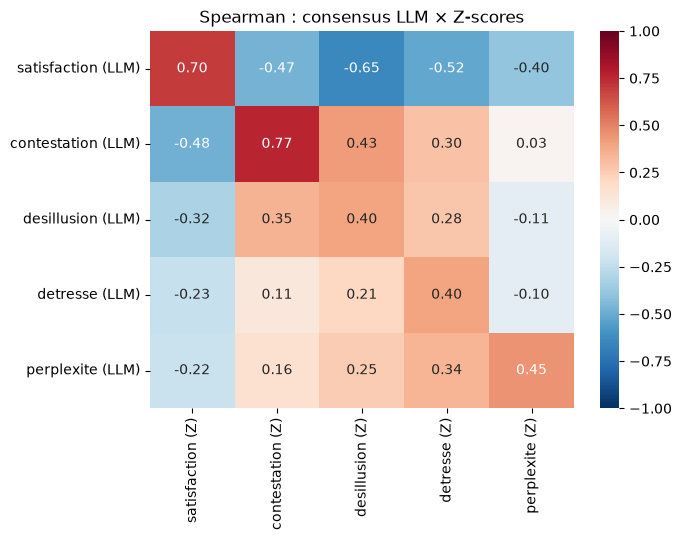

In [18]:
zscores_df = pd.read_csv(ZSCORES_PATH, encoding="utf-8-sig")
check = consensus[["id_experience", *DIMENSIONS]].merge(zscores_df, on="id_experience", suffixes=("_llm", "_z"))
print("Textes appariés :", len(check))

corr = pd.DataFrame(
    [[check[f"{a}_llm"].corr(check[f"{b}_z"], method="spearman") for b in DIMENSIONS] for a in DIMENSIONS],
    index=[f"{d} (LLM)" for d in DIMENSIONS],
    columns=[f"{d} (Z)" for d in DIMENSIONS],
)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Spearman : consensus LLM × Z-scores")
plt.tight_layout()
plt.show()

## Convergence sur présence / absence

In [19]:
SEUILS = [1, 2]   # présent si score >= seuil

rows = []
for seuil in SEUILS:
    for dim in DIMENSIONS:
        scores = wide_df[dim].reindex(columns=available)
        pres = (scores >= seuil).astype(float).where(scores.notna())   # garde les NaN
        complet = pres.dropna()
        n_pres = complet.sum(axis=1)
        rows.append({
            "seuil": f"≥ {seuil}",
            "dimension": dim,
            "alpha": krippendorff_alpha_ordinal(pres.to_numpy().T, categories=(0, 1)),
            "unanimité": ((n_pres == 0) | (n_pres == len(available))).mean(),
            "accord brut moyen (paires)": np.mean([(complet[a] == complet[b]).mean()
                                                   for a, b in combinations(available, 2)]),
            "consensus présent (≥ moitié)": (n_pres >= len(available) / 2).mean(),
            **{f"prév. {s.split('_')[0]}": pres[s].mean() for s in available},
        })
binaire = pd.DataFrame(rows).set_index(["seuil", "dimension"])
display(binaire.round(3))

alpha  unanimité  accord brut moyen (paires)  \
seuil dimension                                                    
≥ 1   satisfaction  0.915      0.940                       0.968   
      contestation  0.593      0.650                       0.801   
      desillusion   0.339      0.514                       0.712   
      detresse      0.549      0.766                       0.868   
      perplexite    0.448      0.502                       0.724   
≥ 2   satisfaction  0.902      0.946                       0.970   
      contestation  0.606      0.656                       0.805   
      desillusion   0.244      0.609                       0.787   
      detresse      0.623      0.926                       0.960   
      perplexite    0.406      0.520                       0.745   

                    consensus présent (≥ moitié)  prév. gemma4  prév. mistral  \
seuil dimension                                                                 
≥ 1   satisfaction                         0.251         0.258          0.244   
      contestation                         0.633         0.443          0.754   
      desillusion                          0.445         0.112          0.476   
      detresse                             0.204         0.110          0.242   
      perplexite                           0.569         0.432          0.538   
≥ 2   satisfaction                         0.199         0.165          0.207   
      contestation                         0.510         0.283          0.600   
      desillusion                          0.174         0.027          0.173   
      detresse                             0.058         0.035          0.096   
      perplexite                           0.291         0.219          0.235   

                    prév. qwen3  prév. eurollm  
seuil dimension                                 
≥ 1   satisfaction        0.236          0.263  
      contestation        0.484          0.608  
      desillusion         0.162          0.533  
      detresse            0.101          0.256  
      perplexite          0.324          0.786  
≥ 2   satisfaction        0.182          0.199  
      contestation        0.390          0.508  
      desillusion         0.075          0.403  
      detresse            0.048          0.047  
      perplexite          0.209          0.581

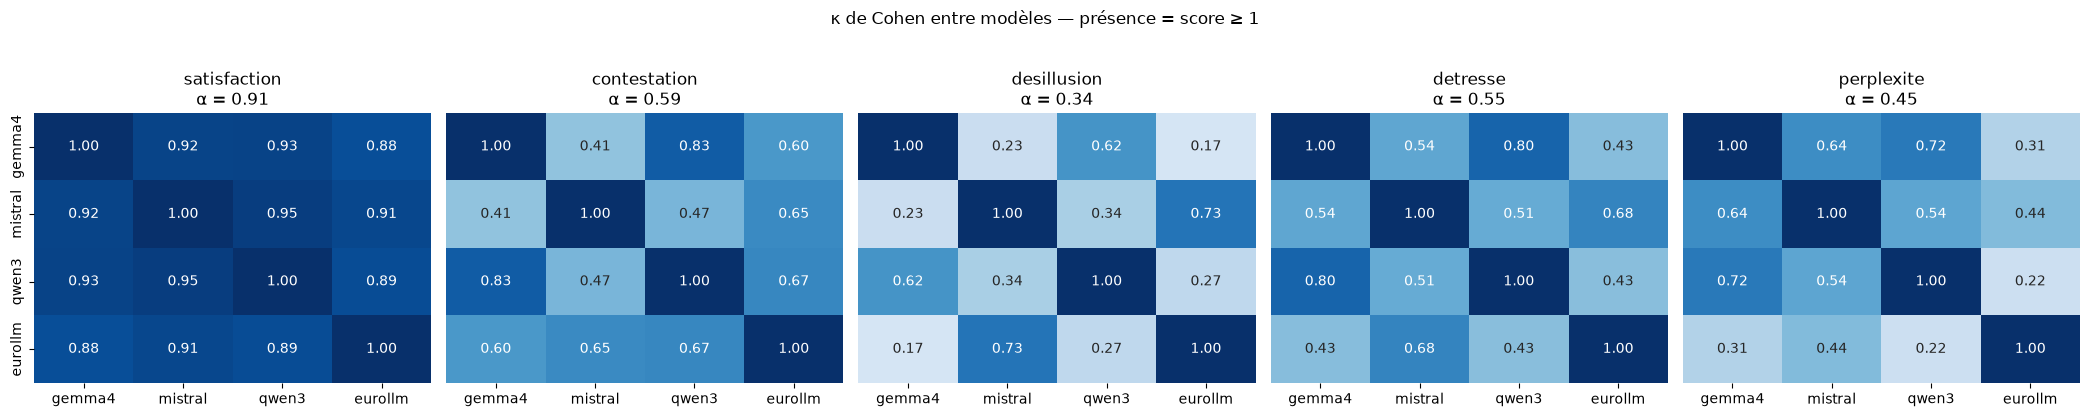

In [20]:
seuil = 1
fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4.2 * len(DIMENSIONS), 4))
for ax, dim in zip(axes, DIMENSIONS):
    pres = (wide_df[dim].reindex(columns=available) >= seuil).astype(float).where(wide_df[dim].notna())
    mat = pd.DataFrame(np.eye(len(available)), index=available, columns=available)
    for a, b in combinations(available, 2):
        pair = pres[[a, b]].dropna()
        mat.loc[a, b] = mat.loc[b, a] = cohen_kappa_score(pair[a], pair[b])
    sns.heatmap(mat, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Blues", cbar=False, ax=ax,
                xticklabels=[s.split("_")[0] for s in available],
                yticklabels=[s.split("_")[0] for s in available] if ax is axes[0] else False)
    ax.set_title(f"{dim}\nα = {binaire.loc[(f'≥ {seuil}', dim), 'alpha']:.2f}")
plt.suptitle(f"κ de Cohen entre modèles — présence = score ≥ {seuil}", y=1.03)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.metrics import roc_auc_score

z = pd.read_csv(ZSCORES_PATH, encoding="utf-8-sig").set_index("id_experience")
rows = []
for dim in DIMENSIONS:
    scores = wide_df[dim].reindex(columns=available)
    present = ((scores >= 1).sum(axis=1) >= len(available) / 2).astype(int)   # consensus LLM
    df = pd.DataFrame({"llm": present}).join(z[dim].rename("z"), how="inner").dropna()
    z_pos = (df["z"] >= 0).astype(int)   # binarisation utilisée dans model_trainer
    rows.append({
        "dimension": dim,
        "prévalence LLM": df["llm"].mean(),
        "prévalence z ≥ 0": z_pos.mean(),
        "accord brut": (df["llm"] == z_pos).mean(),
        "κ (LLM vs z ≥ 0)": cohen_kappa_score(df["llm"], z_pos),
        "AUC du z pour prédire LLM": roc_auc_score(df["llm"], df["z"]),
    })
display(pd.DataFrame(rows).set_index("dimension").round(3))

,prévalence LLM,prévalence z ≥ 0,accord brut,κ (LLM vs z ≥ 0),AUC du z pour prédire LLM
dimension,,,,,
satisfaction,0.251,0.495,0.737,0.471,0.958
contestation,0.633,0.459,0.768,0.546,0.887
desillusion,0.445,0.539,0.744,0.493,0.826
detresse,0.204,0.499,0.654,0.308,0.836
perplexite,0.569,0.510,0.713,0.424,0.784


In [23]:
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, roc_curve, cohen_kappa_score

z = pd.read_csv(ZSCORES_PATH, encoding="utf-8-sig").set_index("id_experience")
RUNS = {"v1": Path("../data/annotations/pilot_10000"),
        "v2": Path("../data/annotations/pilot_10000_v2")}
SEUIL_PRESENCE = {"satisfaction": 1, "contestation": 1, "desillusion": 1, "detresse": 2, "perplexite": 1}

rows = []
for prompt, run_dir in RUNS.items():
    for m in MODELS:
        ann = (pd.read_csv(run_dir / f"{m['slug']}.csv")
               .drop_duplicates("id_experience").set_index("id_experience"))
        for dim in DIMENSIONS:
            df = ann[[dim]].rename(columns={dim: "llm"}).join(z[dim].rename("z"), how="inner").dropna()
            present = (df["llm"] >= SEUIL_PRESENCE[dim]).astype(int)
            fpr, tpr, thr = roc_curve(present, df["z"])
            best = thr[np.argmax(tpr - fpr)]
            rows.append({
                "prompt": prompt, "modèle": m["slug"].split("_")[0], "dimension": dim,
                "ρ Spearman": spearmanr(df["llm"], df["z"])[0],
                "AUC": roc_auc_score(present, df["z"]),
                "κ (z ≥ 0)": cohen_kappa_score(present, (df["z"] >= 0).astype(int)),
                "κ (meilleur seuil)": cohen_kappa_score(present, (df["z"] >= best).astype(int)),
                "meilleur seuil z": best,
            })
accord_z = pd.DataFrame(rows)
accord_z.to_csv("../data/annotations/accord_modeles_zscores.csv", index=False)

for col in ["ρ Spearman", "AUC", "κ (meilleur seuil)"]:
    print(f"\n=== {col}")
    display(accord_z.pivot_table(index="dimension", columns=["prompt", "modèle"], values=col)
            .reindex(DIMENSIONS).round(2))


=== ρ Spearman


prompt            v1                           v2                     
modèle       eurollm gemma4 mistral qwen3 eurollm gemma4 mistral qwen3
dimension                                                             
satisfaction    0.70   0.69    0.71  0.69    0.70   0.69    0.71  0.69
contestation    0.75   0.73    0.76  0.76    0.73   0.71    0.73  0.73
desillusion     0.51   0.45    0.66  0.55    0.57   0.30    0.57  0.37
detresse        0.52   0.45    0.56  0.49    0.48   0.39    0.48  0.38
perplexite      0.40   0.48    0.53  0.45    0.41   0.42    0.50  0.42


=== AUC


prompt            v1                           v2                     
modèle       eurollm gemma4 mistral qwen3 eurollm gemma4 mistral qwen3
dimension                                                             
satisfaction    0.95   0.94    0.97  0.96    0.94   0.95    0.97  0.96
contestation    0.89   0.90    0.87  0.90    0.88   0.88    0.87  0.89
desillusion     0.80   0.80    0.92  0.82    0.83   0.78    0.83  0.79
detresse        0.87   0.86    0.83  0.85    0.87   0.87    0.83  0.85
perplexite      0.76   0.77    0.79  0.76    0.81   0.75    0.78  0.75


=== κ (meilleur seuil)


prompt            v1                           v2                     
modèle       eurollm gemma4 mistral qwen3 eurollm gemma4 mistral qwen3
dimension                                                             
satisfaction    0.79   0.79    0.83  0.83    0.77   0.80    0.83  0.83
contestation    0.63   0.64    0.53  0.64    0.61   0.61    0.54  0.63
desillusion     0.45   0.34    0.66  0.48    0.52   0.23    0.51  0.25
detresse        0.24   0.30    0.33  0.29    0.19   0.15    0.26  0.18
perplexite      0.37   0.41    0.44  0.37    0.39   0.37    0.44  0.34

# comparaison de distributions pour amélioration du prompt

In [24]:
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score, roc_curve, cohen_kappa_score

RUNS = {"v1": Path("../data/annotations/pilot_10000"),
        "v2": Path("../data/annotations/pilot_10000_v2")}
SEUIL_PRESENCE = {"satisfaction": 1, "contestation": 1, "desillusion": 1, "detresse": 1, "perplexite": 1}
Z_ANCRE = 1.0   # z >= +1 : facteur nettement présent ; z <= -1 : nettement absent

z = pd.read_csv(ZSCORES_PATH, encoding="utf-8-sig").set_index("id_experience")
z_long = z[DIMENSIONS].reset_index().melt(id_vars="id_experience", var_name="dimension", value_name="z")

frames = []
for prompt, run_dir in RUNS.items():
    for m in MODELS:
        ann = pd.read_csv(run_dir / f"{m['slug']}.csv").drop_duplicates("id_experience")
        long = ann[["id_experience", *DIMENSIONS]].melt(id_vars="id_experience", var_name="dimension", value_name="score")
        long["prompt"], long["modèle"] = prompt, m["slug"].split("_")[0]
        frames.append(long)
lf = pd.concat(frames).dropna().merge(z_long, on=["id_experience", "dimension"])
lf["score"] = lf["score"].astype(int)

rows = []
for (dim, mod, prompt), d in lf.groupby(["dimension", "modèle", "prompt"]):
    present = (d["score"] >= SEUIL_PRESENCE[dim]).astype(int)
    fpr, tpr, thr = roc_curve(present, d["z"])
    best = thr[np.argmax(tpr - fpr)]
    rows.append({
        "dimension": dim, "modèle": mod, "prompt": prompt,
        "prévalence LLM": present.mean(),
        "ρ": spearmanr(d["score"], d["z"])[0],
        "κ (meilleur seuil)": cohen_kappa_score(present, (d["z"] >= best).astype(int)),
        "seuil z équivalent": best,
        f"manqués (z ≥ {Z_ANCRE:g}, absent)": 1 - present[d["z"] >= Z_ANCRE].mean(),
        f"fausses alertes (z ≤ -{Z_ANCRE:g}, présent)": present[d["z"] <= -Z_ANCRE].mean(),
    })
diag = pd.DataFrame(rows).set_index(["dimension", "modèle", "prompt"]).reindex(DIMENSIONS, level=0)
diag.to_csv("../data/annotations/diagnostic_strictesse.csv")
display(diag.round(2))

prévalence LLM     ρ  κ (meilleur seuil)  \
dimension    modèle  prompt                                             
satisfaction eurollm v1                0.25  0.70                0.79   
                     v2                0.26  0.70                0.77   
             gemma4  v1                0.26  0.69                0.79   
                     v2                0.26  0.69                0.80   
             mistral v1                0.24  0.71                0.83   
                     v2                0.24  0.71                0.83   
             qwen3   v1                0.24  0.69                0.83   
                     v2                0.24  0.69                0.83   
contestation eurollm v1                0.60  0.75                0.63   
                     v2                0.61  0.73                0.61   
             gemma4  v1                0.45  0.73                0.64   
                     v2                0.44  0.71                0.61   
             mistral v1                0.76  0.76                0.53   
                     v2                0.75  0.73                0.54   
             qwen3   v1                0.57  0.76                0.64   
                     v2                0.48  0.73                0.63   
desillusion  eurollm v1                0.41  0.51                0.45   
                     v2                0.53  0.57                0.52   
             gemma4  v1                0.26  0.45                0.34   
                     v2                0.11  0.30                0.23   
             mistral v1                0.68  0.66                0.66   
                     v2                0.48  0.57                0.51   
             qwen3   v1                0.41  0.55                0.48   
                     v2                0.16  0.37                0.25   
detresse     eurollm v1                0.41  0.52                0.43   
                     v2                0.26  0.48                0.37   
             gemma4  v1                0.17  0.45                0.40   
                     v2                0.11  0.39                0.34   
             mistral v1                0.42  0.56                0.46   
                     v2                0.24  0.48                0.40   
             qwen3   v1                0.23  0.49                0.41   
                     v2                0.10  0.38                0.33   
perplexite   eurollm v1                0.71  0.40                0.37   
                     v2                0.79  0.41                0.39   
             gemma4  v1                0.54  0.48                0.41   
                     v2                0.43  0.42                0.37   
             mistral v1                0.62  0.53                0.44   
                     v2                0.54  0.50                0.44   
             qwen3   v1                0.38  0.45                0.37   
                     v2                0.32  0.42                0.34   

                             seuil z équivalent  manqués (z ≥ 1, absent)  \
dimension    modèle  prompt                                                
satisfaction eurollm v1                    0.76                     0.07   
                     v2                    0.71                     0.06   
             gemma4  v1                    0.84                     0.07   
                     v2                    0.84                     0.07   
             mistral v1                    0.83                     0.06   
                     v2                    0.84                     0.06   
             qwen3   v1                    0.84                     0.07   
                     v2                    0.84                     0.08   
contestation eurollm v1                   -0.28                     0.02   
                     v2                   -0.28                     0.02   
             gemma4  v1                    0.14   

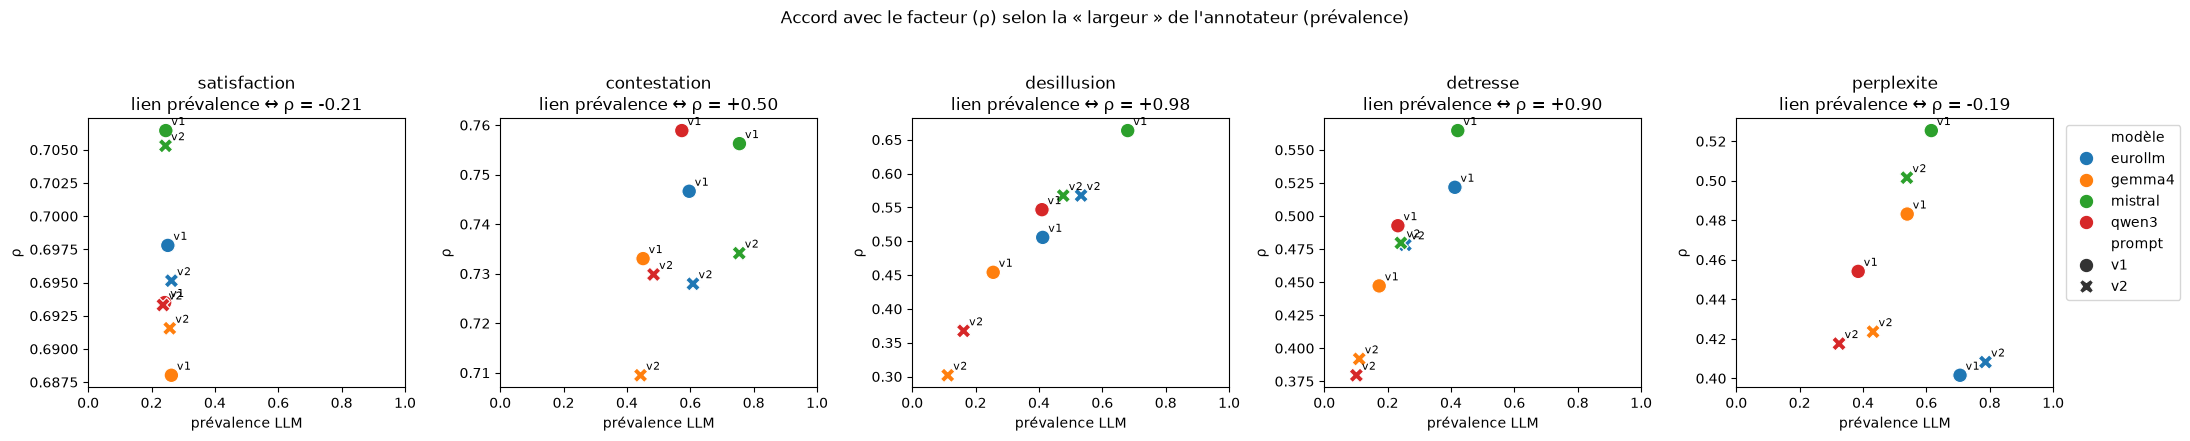

,lien prévalence ↔ ρ,verdict,meilleur annotateur,ρ max,prévalence du meilleur
satisfaction,-0.214286,indéterminé,mistral v1,0.706446,0.245
contestation,0.5,assouplir,qwen3 v1,0.758892,0.5732
desillusion,0.97619,assouplir,mistral v1,0.66352,0.68
detresse,0.904762,assouplir,mistral v1,0.564589,0.4213
perplexite,-0.190476,indéterminé,mistral v1,0.525397,0.6154


In [25]:
verdicts = {}
fig, axes = plt.subplots(1, len(DIMENSIONS), figsize=(4.4 * len(DIMENSIONS), 4.2))
for ax, dim in zip(axes, DIMENSIONS):
    d = diag.loc[dim].reset_index()
    sns.scatterplot(data=d, x="prévalence LLM", y="ρ", hue="modèle", style="prompt", s=110, ax=ax,
                    legend=(ax is axes[-1]))
    for _, r in d.iterrows():
        ax.annotate(r["prompt"], (r["prévalence LLM"], r["ρ"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
    lien = spearmanr(d["prévalence LLM"], d["ρ"])[0]
    verdicts[dim] = {"lien prévalence ↔ ρ": lien,
                     "verdict": "assouplir" if lien > 0.5 else "durcir" if lien < -0.5 else "indéterminé",
                     "meilleur annotateur": " ".join(d.loc[d["ρ"].idxmax(), ["modèle", "prompt"]]),
                     "ρ max": d["ρ"].max(),
                     "prévalence du meilleur": d.loc[d["ρ"].idxmax(), "prévalence LLM"]}
    ax.set_title(f"{dim}\nlien prévalence ↔ ρ = {lien:+.2f}")
    ax.set_xlim(0, 1)
if axes[-1].get_legend():
    sns.move_legend(axes[-1], "upper left", bbox_to_anchor=(1.02, 1))
plt.suptitle("Accord avec le facteur (ρ) selon la « largeur » de l'annotateur (prévalence)", y=1.04)
plt.tight_layout()
plt.show()
display(pd.DataFrame(verdicts).T.reindex(DIMENSIONS).round(2))

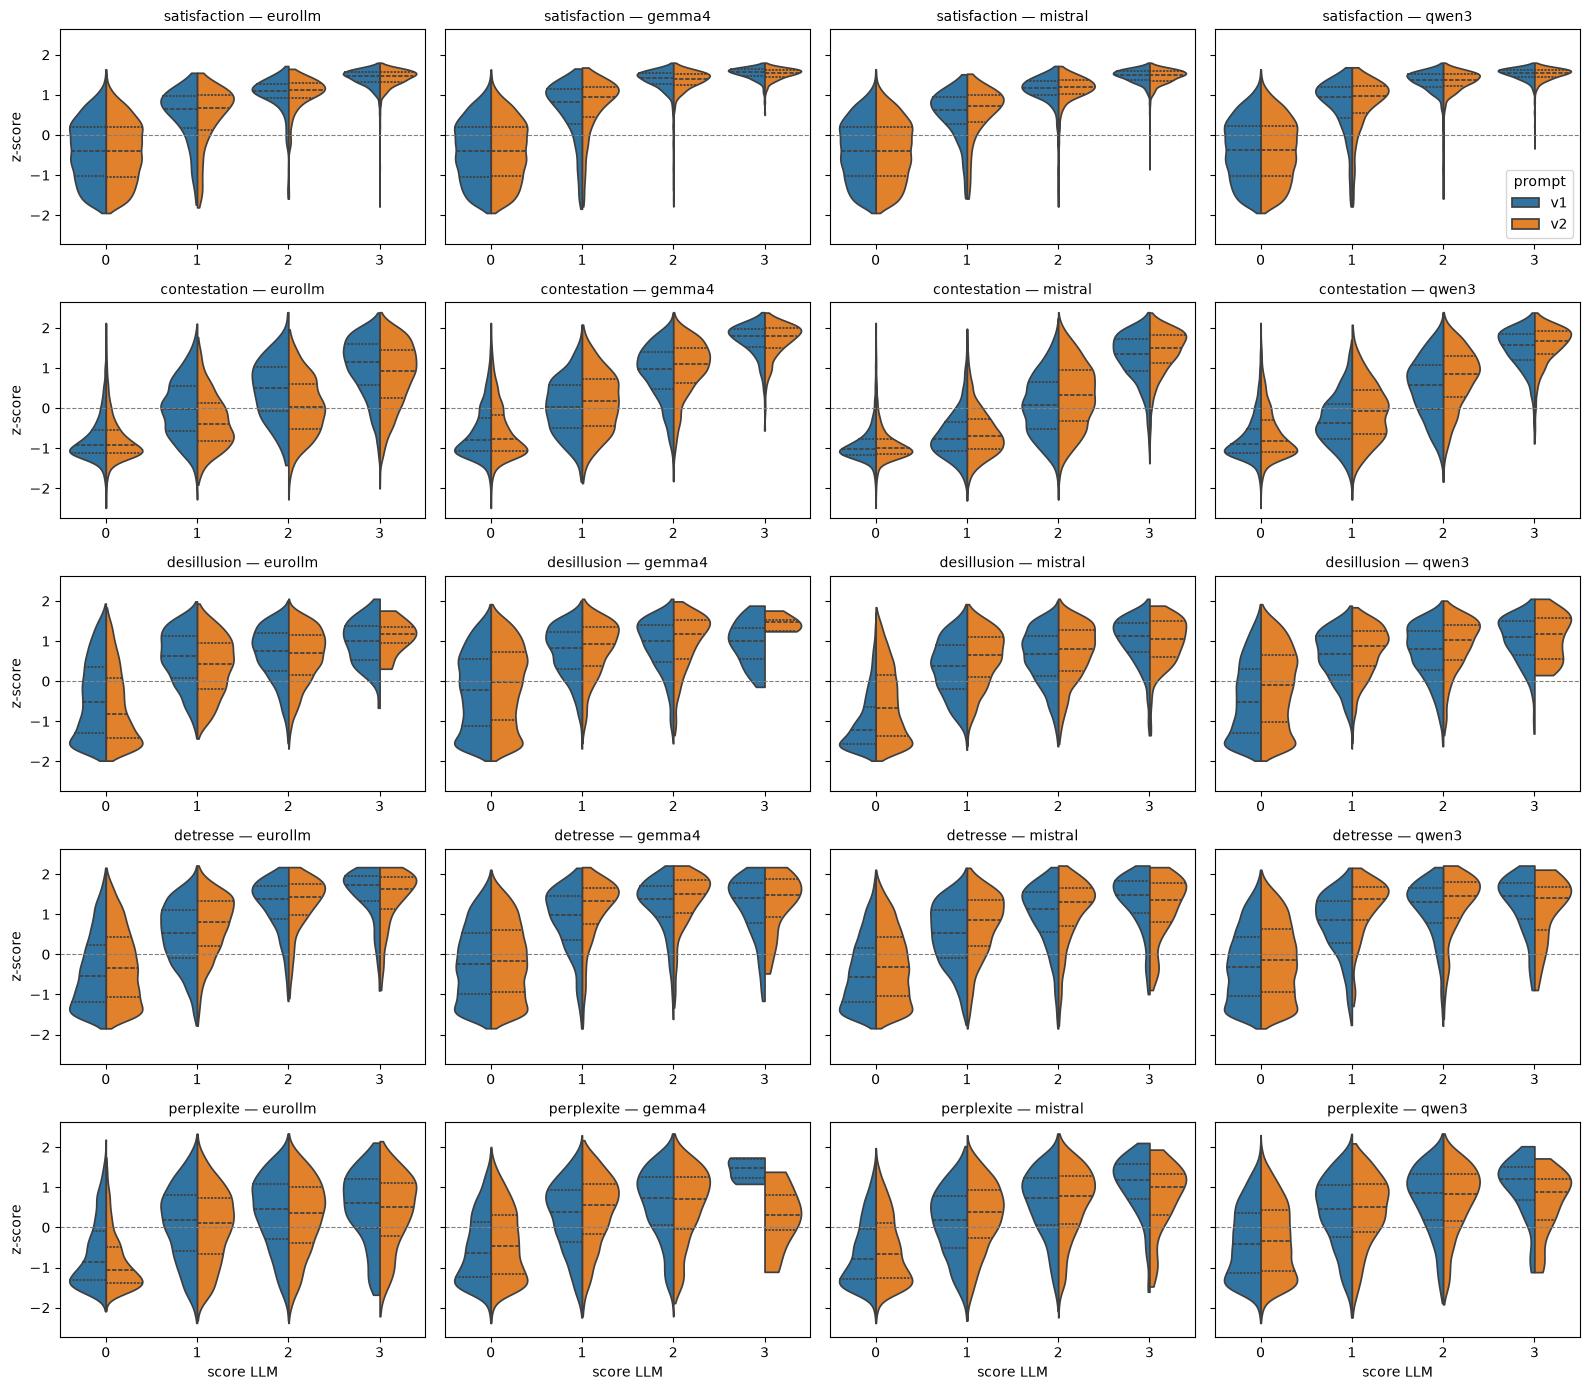

In [26]:
modeles = sorted(lf["modèle"].unique())
fig, axes = plt.subplots(len(DIMENSIONS), len(modeles), figsize=(4 * len(modeles), 2.8 * len(DIMENSIONS)),
                         sharey=True)
for i, dim in enumerate(DIMENSIONS):
    for j, mod in enumerate(modeles):
        ax = axes[i, j]
        d = lf[(lf["dimension"] == dim) & (lf["modèle"] == mod)]
        sns.violinplot(data=d, x="score", y="z", hue="prompt", hue_order=list(RUNS), order=[0, 1, 2, 3],
                       split=True, inner="quart", cut=0, density_norm="width", ax=ax,
                       legend=(i == 0 and j == len(modeles) - 1))
        ax.axhline(0, color="grey", lw=0.8, ls="--")
        ax.set_title(f"{dim} — {mod}", fontsize=10)
        ax.set_xlabel("score LLM" if i == len(DIMENSIONS) - 1 else "")
        ax.set_ylabel("z-score" if j == 0 else "")
plt.tight_layout()
plt.show()

# Recherche du Z optimal par dimension avec indice de Youden

In [22]:
from sklearn.metrics import roc_curve

SEUIL_PRESENCE = {"satisfaction": 1, "contestation": 1, "desillusion": 1, "detresse": 2, "perplexite": 1}
rows = []
for dim in DIMENSIONS:
    scores = wide_df[dim].reindex(columns=available)
    llm = ((scores >= SEUIL_PRESENCE[dim]).sum(axis=1) >= len(available) / 2).astype(int)
    df = pd.DataFrame({"llm": llm}).join(z[dim].rename("z"), how="inner").dropna()
    fpr, tpr, thr = roc_curve(df["llm"], df["z"])
    candidats = {
        "z ≥ 0": 0.0,
        "Youden": thr[np.argmax(tpr - fpr)],
        "même prévalence": df["z"].quantile(1 - df["llm"].mean()),
    }
    for nom, t in candidats.items():
        pred = (df["z"] >= t).astype(int)
        rows.append({"dimension": dim, "méthode": nom, "seuil z": t,
                     "prévalence": pred.mean(), "κ vs LLM": cohen_kappa_score(df["llm"], pred),
                     "accord": (pred == df["llm"]).mean()})
seuils = pd.DataFrame(rows).set_index(["dimension", "méthode"]).round(3)
display(seuils)
seuils.to_csv(OUT_DIR / "seuils_z.csv")

seuil z  prévalence  κ vs LLM  accord
dimension    méthode                                               
satisfaction z ≥ 0              0.000       0.495     0.471   0.737
             Youden             0.839       0.244     0.825   0.935
             même prévalence    0.805       0.251     0.815   0.930
contestation z ≥ 0              0.000       0.459     0.546   0.768
             Youden            -0.279       0.535     0.605   0.806
             même prévalence   -0.594       0.633     0.610   0.819
desillusion  z ≥ 0              0.000       0.539     0.493   0.744
             Youden             0.012       0.535     0.495   0.746
             même prévalence    0.303       0.445     0.479   0.743
detresse     z ≥ 0              0.000       0.499     0.094   0.548
             Youden             0.828       0.252     0.220   0.781
             même prévalence    1.585       0.058     0.362   0.930
perplexite   z ≥ 0              0.000       0.510     0.424   0.713
             Youden            -0.094       0.540     0.433   0.720
             même prévalence   -0.199       0.569     0.434   0.722